# Token Counts and Text Preprocessing

**Scope:** Measure how tokenizer selection, document serialization, and field-value preprocessing affect the number of token IDs produced from a small synthetic corpus.

**Research questions:**

1. How many token IDs do different tokenizers produce for identical input strings?
2. How do the chosen plain-text, Markdown, HTML, and JSON templates affect token counts for the same source fields?
3. How do lowercasing, punctuation replacement, Unicode normalization, and whitespace collapsing affect token counts and text preservation?


This is a deterministic, exploratory measurement exercise, not a representative benchmark of model quality, inference performance, provider billing, or all possible text in any language. All tokenizers receive the same serialized input for a given condition, but their token IDs and vocabulary conventions are not interchangeable.

### Environment and measurement rules

**Dependencies:** `transformers`, `tokenizers`, `pandas`, `matplotlib`, and, when required by the tokenizer backend, `sentencepiece`. Loading uncached tokenizer artifacts requires access to Hugging Face.


Each measurement uses `tokenizer.encode(text, add_special_tokens=False)`. No model weights are loaded, and no model inference takes place. Padding, explicit truncation, chat templates, and the automatic addition of special tokens are excluded. Input length and tokenizer configuration can still affect how an individual tokenizer handles a string.


The input strings are the unit of comparison: they are not full chat requests, and their token counts cannot be substituted directly for API billing. Metadata and file hashes are recorded for traceability, but upstream model repository revisions are not pinned by this notebook.

In [1]:
import json
import platform
import unicodedata
from hashlib import sha256
from html import escape
from importlib.metadata import PackageNotFoundError, version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from transformers import AutoTokenizer

pd.set_option("display.max_colwidth", 100)


def package_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "not installed"


print(f"Python: {platform.python_version()}")
for package_name in (
    "transformers",
    "tokenizers",
    "pandas",
    "matplotlib",
    "sentencepiece",
):
    print(f"{package_name}: {package_version(package_name)}")


Python: 3.12.3
transformers: 5.17.0
tokenizers: 0.23.2
pandas: 3.0.6
matplotlib: 3.11.2
sentencepiece: 0.2.2


### Tokenizers and synthetic source cases

In [2]:
TOKENIZER_MODELS = {
    "Qwen2.5 Instruct": "Qwen/Qwen2.5-0.5B-Instruct",
    "SmolLM2 Instruct": "HuggingFaceTB/SmolLM2-360M-Instruct",
    "mBERT cased": "google-bert/bert-base-multilingual-cased",
    "mT5": "google/mt5-small",
}

SOURCE_CASES = [
    {
        "case_id": "pt_accents_numbers",
        "feature": "Portuguese, accents, numbers",
        "fields": {
            "Title": "Análise de custos da inferência",
            "Description": "O serviço processa 1.250 pedidos/dia em São Paulo; custo de R$ 49,90.",
            "Tags": "tokens, memória, GPU",
        },
    },
    {
        "case_id": "en_technical",
        "feature": "English, technical identifiers, irregular whitespace",
        "fields": {
            "Title": "API response validation",
            "Description": "Return HTTP 200 on success and HTTP 429 after rate limiting; log user_id.",
            "Tags": "latency,   retry,  status_code",
        },
    },
    {
        "case_id": "html_sensitive",
        "feature": "HTML-sensitive characters",
        "fields": {
            "Title": "Café & código",
            "Description": 'Use x < y and y > z; compare "A" with "B".',
            "Tags": "HTML, JSON, escaping",
        },
    },
    {
        "case_id": "unicode_decomposed",
        "feature": "Mixed Unicode containing decomposed accents",
        "fields": {
            "Title": "Cafe\u0301 e corac\u0327a\u0303o",
            "Description": "A normalizac\u0327a\u0303o Unicode pode alterar a segmentação.",
            "Tags": "acentos, Unicode, NFD",
        },
    },
    {
        "case_id": "unicode_compatibility",
        "feature": "Unicode compatibility characters",
        "fields": {
            "Title": "ＡＰＩ e ① teste",
            "Description": "Texto com caracteres de largura cheia: ＡＢＣ e １２３.",
            "Tags": "compatibilidade, NFKC, Unicode",
        },
    },
    {
        "case_id": "paths_punctuation",
        "feature": "Punctuation, paths, query parameters",
        "fields": {
            "Title": "Logs: errors, warnings...",
            "Description": 'Path /api/v1/items?limit=10&sort=asc; file name "report-v2.json".',
            "Tags": "slashes, punctuation, paths",
        },
    },
]

FIELD_NAMES = ("Title", "Description", "Tags")
TEXT_FORMATS = ("plain", "markdown", "html", "json")

if len({case["case_id"] for case in SOURCE_CASES}) != len(SOURCE_CASES):
    raise ValueError("Case IDs must be unique.")

if any(tuple(case["fields"]) != FIELD_NAMES for case in SOURCE_CASES):
    raise ValueError("Every case must contain the same ordered fields.")

### Serialization templates

Each case is rendered using the same ordered field names and values. The templates differ in punctuation, markup, escaping, and whitespace. The resulting comparisons describe these templates, not intrinsic costs of Markdown, HTML, or JSON in general. In particular, the JSON template uses two-space indentation, while the HTML template includes an `<article>` wrapper and escaped text nodes.

The Markdown template is intentionally simple and does not escape Markdown syntax inside field values. It is valid as a token-count input but does not guarantee identical rendered appearance for arbitrary values. The plain-text representation is not a lossless structured-data format in general.

In [3]:
def render_text(fields, text_format):
    if text_format == "plain":
        return "\n".join(f"{name}: {fields[name]}" for name in FIELD_NAMES)

    if text_format == "markdown":
        return "\n\n".join(f"**{name}:** {fields[name]}" for name in FIELD_NAMES)

    if text_format == "html":
        body = "\n".join(
            f"  <p><strong>{name}:</strong> {escape(fields[name], quote=False)}</p>"
            for name in FIELD_NAMES
        )
        return f"<article>\n{body}\n</article>"

    if text_format == "json":
        return json.dumps(fields, ensure_ascii=False, indent=2)

    raise ValueError(f"Unsupported text format: {text_format}")


for case in SOURCE_CASES:
    serialized = render_text(case["fields"], "json")
    if json.loads(serialized) != case["fields"]:
        raise ValueError(f"JSON serialization changed a source case: {case['case_id']}")

## Field-value transformations

Transformations operate only on field values before serialization. Field names, JSON syntax, and HTML structural markup are not transformed. The seven conditions are: unchanged values, lowercase, replacement of Unicode-category punctuation with spaces, NFC, NFKC, whitespace collapsing, and lowercase followed by punctuation replacement.

Punctuation replacement also collapses whitespace through `split()`/`join()`. Unicode punctuation classes (`P*`) do not include every symbol, such as mathematical operators or currency symbols. Thus, a transformed string can retain `=` or `R$` while losing a slash, decimal separator, or question mark.

NFC and NFKC are different:

- NFC performs canonical normalization
- NFKC also applies compatibility transformations, which can change characters such as `①` into `1`.

Transforming a field may change its meaning even if the resulting JSON is still syntactically valid.

In [4]:
def replace_punctuation_with_spaces(text):
    replaced = "".join(
        " " if unicodedata.category(character).startswith("P") else character
        for character in text
    )
    return " ".join(replaced.split())


def collapse_whitespace(text):
    return " ".join(text.split())


def lowercase_and_replace_punctuation(text):
    return replace_punctuation_with_spaces(text.lower())


TRANSFORMATIONS = {
    "original": lambda text: text,
    "lowercase": str.lower,
    "punctuation_to_spaces": replace_punctuation_with_spaces,
    "normalize_nfc": lambda text: unicodedata.normalize("NFC", text),
    "normalize_nfkc": lambda text: unicodedata.normalize("NFKC", text),
    "collapse_whitespace": collapse_whitespace,
    "lowercase_and_punctuation": lowercase_and_replace_punctuation,
}


def transform_fields(fields, transformation):
    try:
        transform = TRANSFORMATIONS[transformation]
    except KeyError as exc:
        raise ValueError(f"Unknown transformation: {transformation}") from exc
    return {name: transform(fields[name]) for name in FIELD_NAMES}


# Sanity checks target the transformations' intended behavior.
assert unicodedata.normalize("NFC", "Cafe\u0301") == "Café"
assert unicodedata.normalize("NFKC", "①") == "1"
assert replace_punctuation_with_spaces("/api/v1?limit=10") == "api v1 limit=10"
assert collapse_whitespace("a   b\n c") == "a b c"

## Generate the experimental inputs

The factorial design contains 6 source cases × 7 transformation conditions × 4 serialization templates = 168 input conditions. Each condition is passed to all four tokenizers, producing 672 measurements. 

Some transformations have no effect on particular fields, so 168 conditions do not imply 168 distinct input strings. The SHA-256 digest describes the exact UTF-8 bytes of a serialized string, not the token IDs.

There is no random sampling. To reproduce the *same tokenizer results* in a future environment, one must also control the tokenizer revisions and library behavior; dependency versions and any available repository revision metadata are logged below.

In [5]:
formatted_inputs = []

for case in SOURCE_CASES:
    for transformation in TRANSFORMATIONS:
        fields = transform_fields(case["fields"], transformation)

        for text_format in TEXT_FORMATS:
            serialized_text = render_text(fields, text_format)
            encoded_bytes = serialized_text.encode("utf-8")

            formatted_inputs.append(
                {
                    "case_id": case["case_id"],
                    "feature": case["feature"],
                    "format": text_format,
                    "transformation": transformation,
                    "text": serialized_text,
                    "text_sha256": sha256(encoded_bytes).hexdigest(),
                    "character_count": len(serialized_text),
                    "utf8_byte_count": len(encoded_bytes),
                }
            )

inputs_df = pd.DataFrame.from_records(formatted_inputs)
expected_conditions = len(SOURCE_CASES) * len(TEXT_FORMATS) * len(TRANSFORMATIONS)

if len(inputs_df) != expected_conditions:
    raise RuntimeError("The number of input conditions is incorrect.")

if inputs_df.duplicated(["case_id", "format", "transformation"]).any():
    raise RuntimeError("Duplicate experimental condition keys were found.")

print(f"\nExperimental conditions: {len(inputs_df)}")
print(f"Distinct serialized strings: {inputs_df['text_sha256'].nunique()}")
print(f"Expected token-count measurements: {len(inputs_df) * len(TOKENIZER_MODELS)}")


Experimental conditions: 168
Distinct serialized strings: 108
Expected token-count measurements: 672


## Load tokenizers and record metadata

Each tokenizer is loaded with `use_fast=True` and `trust_remote_code=False`, without loading model weights. The experiment fails explicitly if a tokenizer cannot be loaded; it does not silently omit a requested tokenizer.

`resolved_commit_hash` is included only if exposed by the installed library. A missing hash must not be interpreted as a pinned or verified revision.

Tokenizer families differ: mBERT is a WordPiece encoder tokenizer, mT5 uses a SentencePiece-family tokenizer, and Qwen2.5 and SmolLM2 use tokenizer configurations intended for generative language models.

The comparison concerns token counts for fixed strings, not interchangeable model inputs or comparable model-task performance.

In [6]:
tokenizers = {}
tokenizer_metadata = []

for tokenizer_name, model_id in TOKENIZER_MODELS.items():
    print(f"Loading {tokenizer_name}: {model_id}\n")

    try:
        tokenizer = AutoTokenizer.from_pretrained(
            model_id,
            use_fast=True,
            trust_remote_code=False,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not load tokenizer for {model_id}. "
            "Check the model ID, network/cache access, and required dependencies."
        ) from exc

    tokenizers[tokenizer_name] = tokenizer
    init_kwargs = getattr(tokenizer, "init_kwargs", {})

    tokenizer_metadata.append(
        {
            "tokenizer": tokenizer_name,
            "model_id": model_id,
            "tokenizer_class": type(tokenizer).__name__,
            "is_fast": bool(getattr(tokenizer, "is_fast", False)),
            "vocab_size": tokenizer.vocab_size,
            "resolved_commit_hash": init_kwargs.get("_commit_hash"),
        }
    )

if set(tokenizers) != set(TOKENIZER_MODELS):
    raise RuntimeError("Some tokenizer configurations were not loaded.")

display(pd.DataFrame.from_records(tokenizer_metadata).style.hide(axis="index"))

Loading Qwen2.5 Instruct: Qwen/Qwen2.5-0.5B-Instruct



Loading SmolLM2 Instruct: HuggingFaceTB/SmolLM2-360M-Instruct

Loading mBERT cased: google-bert/bert-base-multilingual-cased

Loading mT5: google/mt5-small



tokenizer,model_id,tokenizer_class,is_fast,vocab_size,resolved_commit_hash
Qwen2.5 Instruct,Qwen/Qwen2.5-0.5B-Instruct,Qwen2Tokenizer,True,151643,None
SmolLM2 Instruct,HuggingFaceTB/SmolLM2-360M-Instruct,GPT2Tokenizer,True,49152,None
mBERT cased,google-bert/bert-base-multilingual-cased,BertTokenizer,True,119547,None
mT5,google/mt5-small,T5Tokenizer,True,250100,None


In [7]:
measurements = []

for tokenizer_name, tokenizer in tokenizers.items():
    unknown_token_id = tokenizer.unk_token_id
    for item in formatted_inputs:
        token_ids = tokenizer.encode(item["text"], add_special_tokens=False)

        decoded_text = tokenizer.decode(
            token_ids,
            skip_special_tokens=False,
            clean_up_tokenization_spaces=False,
        )

        token_count = len(token_ids)

        measurements.append(
            {
                "tokenizer": tokenizer_name,
                "model_id": TOKENIZER_MODELS[tokenizer_name],
                **item,
                "token_count": token_count,
                "unknown_token_count": (
                    sum(token_id == unknown_token_id for token_id in token_ids)
                    if unknown_token_id is not None
                    else 0
                ),
                "roundtrip_exact": decoded_text == item["text"],
                "roundtrip_nfc_equal": (
                    unicodedata.normalize("NFC", decoded_text)
                    == unicodedata.normalize("NFC", item["text"])
                ),
                "characters_per_token": (
                    item["character_count"] / token_count if token_count else float("nan")
                ),
            }
        )

measurements_df = pd.DataFrame.from_records(measurements)

if len(measurements_df) != len(formatted_inputs) * len(tokenizers):
    raise RuntimeError("The number of token measurements is incorrect.")

if measurements_df.duplicated(["case_id", "format", "transformation", "tokenizer"]).any():
    raise RuntimeError("Duplicate measurement keys were found.")

if (measurements_df["unknown_token_count"] > measurements_df["token_count"]).any():
    raise RuntimeError("Unknown-token counts exceed total token counts.")

if (
    not measurements_df.groupby(["case_id", "format", "transformation"])["text_sha256"]
    .nunique()
    .eq(1)
    .all()
):
    raise RuntimeError("Input strings differ across tokenizers for a matched condition.")

if (
    not measurements_df.groupby(["case_id", "format", "transformation"])["tokenizer"]
    .nunique()
    .eq(len(tokenizers))
    .all()
):
    raise RuntimeError("At least one condition is missing a tokenizer measurement.")

print(f"Measured tokenizer-condition pairs: {len(measurements_df)}")
display(
    measurements_df.loc[
        measurements_df["format"].eq("plain")
        & measurements_df["transformation"].eq("original"),
        ["case_id", "tokenizer", "token_count", "unknown_token_count", "roundtrip_exact"],
    ]
    .reset_index(drop=True)
    .style.hide(axis="index")
)


Measured tokenizer-condition pairs: 672


case_id,tokenizer,token_count,unknown_token_count,roundtrip_exact
pt_accents_numbers,Qwen2.5 Instruct,52,0,True
en_technical,Qwen2.5 Instruct,40,0,True
html_sensitive,Qwen2.5 Instruct,32,0,True
unicode_decomposed,Qwen2.5 Instruct,29,0,False
unicode_compatibility,Qwen2.5 Instruct,44,0,True
paths_punctuation,Qwen2.5 Instruct,41,0,True
pt_accents_numbers,SmolLM2 Instruct,61,0,True
en_technical,SmolLM2 Instruct,43,0,True
html_sensitive,SmolLM2 Instruct,37,0,True
unicode_decomposed,SmolLM2 Instruct,49,0,True


## RQ1: Tokenizer selection on identical strings

For each source case, the original plain-text string is passed unchanged to every tokenizer. The table records token-count differences across tokenizer configurations. The difference between the minimum and maximum is a descriptive range, not a quality or cost ranking. `roundtrip_exact` is inspected later to reveal a separate representation issue that token counts and `<unk>` counts do not capture.

In [8]:
plain_baseline = measurements_df.loc[
    measurements_df["format"].eq("plain")
    & measurements_df["transformation"].eq("original")
]

plain_comparison = plain_baseline.pivot(
    index="case_id", columns="tokenizer", values="token_count"
).reindex(columns=list(TOKENIZER_MODELS))

variation = plain_comparison.assign(
    min_tokens=plain_comparison.min(axis=1),
    max_tokens=plain_comparison.max(axis=1),
)
variation["token_range"] = variation["max_tokens"] - variation["min_tokens"]

print("\nToken counts for identical plain-text strings:")
display(plain_comparison)

print("\nRange across tokenizer configurations:")
display(variation[["min_tokens", "max_tokens", "token_range"]])

widest_case = variation["token_range"].idxmax()
print(
    f"\nLargest range in this corpus: {widest_case} "
    f"({variation.at[widest_case, 'min_tokens']} to "
    f"{variation.at[widest_case, 'max_tokens']} tokens)."
)


Token counts for identical plain-text strings:


tokenizer,Qwen2.5 Instruct,SmolLM2 Instruct,mBERT cased,mT5
case_id,,,,
en_technical,40,43,38,37
html_sensitive,32,37,37,37
paths_punctuation,41,49,56,51
pt_accents_numbers,52,61,45,47
unicode_compatibility,44,60,38,37
unicode_decomposed,29,49,39,33



Range across tokenizer configurations:


tokenizer,min_tokens,max_tokens,token_range
case_id,,,
en_technical,37,43,6
html_sensitive,32,37,5
paths_punctuation,41,56,15
pt_accents_numbers,45,61,16
unicode_compatibility,37,60,23
unicode_decomposed,29,49,20



Largest range in this corpus: unicode_compatibility (37 to 60 tokens).


**RQ1 conclusion.** Token counts vary across tokenizer configurations even when input bytes are identical. In the recorded input run, the six plain-text cases ranged from 5 to 23 token IDs between the smallest and largest tokenizer counts for each case. The maximum range occurred for the Unicode compatibility example (37 to 60 IDs).

These observations are corpus-specific; they do not establish which model would provide better responses, lower inference latency, or cheaper billed requests. The `roundtrip_exact` check below separately examines whether the original string can be recovered by decoding.

## RQ2: Serialization format and token-count overhead

Only original field values are compared here. Each tokenizer's counts are summed across the same six cases, separately for each text format. The percent difference is relative to that tokenizer's own plain-text total:

$$
\Delta_{\mathrm{format}}(\%) = 100 \times \frac{T_{\mathrm{format}} - T_{\mathrm{plain}}}{T_{\mathrm{plain}}}
$$

These totals weight each synthetic case once. They are not averages over natural documents or a benchmark of serialization efficiency in general. All syntax, escaping, indentation, and wrapper markup count as input text.

In [9]:
original_inputs_df = measurements_df.loc[measurements_df["transformation"].eq("original")]

format_summary = original_inputs_df.groupby(["tokenizer", "format"], as_index=False).agg(
    total_tokens=("token_count", "sum"),
    mean_tokens=("token_count", "mean"),
)

plain_totals = format_summary.loc[
    format_summary["format"].eq("plain"), ["tokenizer", "total_tokens"]
].rename(columns={"total_tokens": "plain_total_tokens"})

format_summary = format_summary.merge(
    plain_totals, on="tokenizer", validate="many_to_one"
)

format_summary["percent_vs_plain"] = (
    100
    * (format_summary["total_tokens"] - format_summary["plain_total_tokens"])
    / format_summary["plain_total_tokens"]
)

format_count_table = format_summary.pivot(
    index="format", columns="tokenizer", values="total_tokens"
).reindex(index=TEXT_FORMATS, columns=list(TOKENIZER_MODELS))

format_percent_table = format_summary.pivot(
    index="format", columns="tokenizer", values="percent_vs_plain"
).reindex(index=TEXT_FORMATS, columns=list(TOKENIZER_MODELS))

print("\nTotal token IDs across the six original source cases:")
display(format_count_table)
print("\nPercentage relative to each tokenizer's plain-text total:")
display(format_percent_table.round(2))



Total token IDs across the six original source cases:


tokenizer,Qwen2.5 Instruct,SmolLM2 Instruct,mBERT cased,mT5
format,,,,
plain,238,299,253,242
markdown,256,329,325,278
html,451,553,558,480
json,314,375,355,310



Percentage relative to each tokenizer's plain-text total:


tokenizer,Qwen2.5 Instruct,SmolLM2 Instruct,mBERT cased,mT5
format,,,,
plain,0.00,0.00,0.00,0.00
markdown,7.56,10.03,28.46,14.88
html,89.50,84.95,120.55,98.35
json,31.93,25.42,40.32,28.10


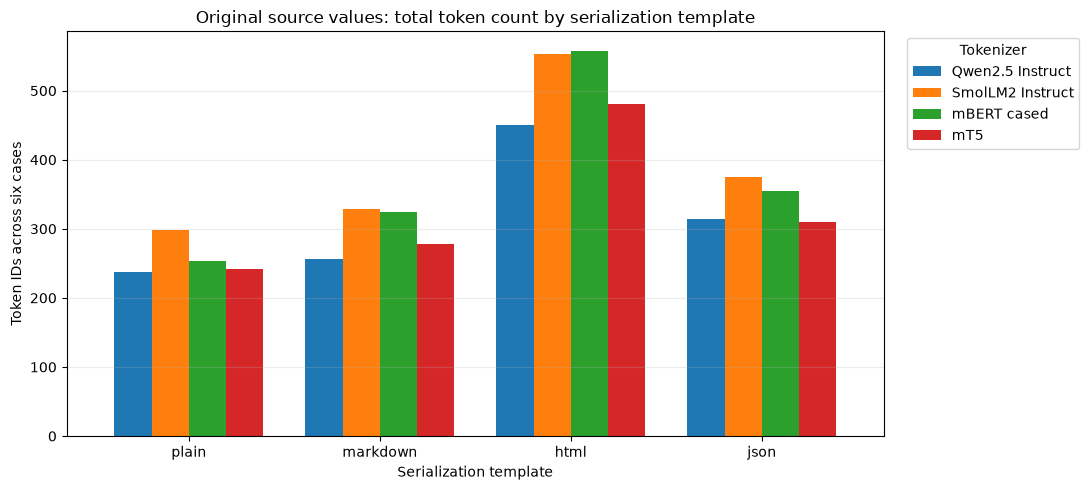

In [10]:
axis = format_count_table.plot(kind="bar", figsize=(11, 5), rot=0, width=0.78)
axis.set_title("Original source values: total token count by serialization template")
axis.set_xlabel("Serialization template")
axis.set_ylabel("Token IDs across six cases")
axis.legend(title="Tokenizer", bbox_to_anchor=(1.02, 1), loc="upper left")
axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

**RQ2 conclusion**

For the six inputs in the provided run, the chosen Markdown, HTML, and JSON templates all used more token IDs in aggregate than the chosen plain-text template for every tokenizer. HTML had the largest aggregate overhead: approximately **85% to 121%**, compared with **8% to 28% for Markdown** and **25% to 40% for JSON** (rounded across tokenizers). This is a statement about the *specific templates and corpus*; different field names, markup, indentation, escape rules, and content could reverse individual comparisons. Fewer tokens also do not imply that a representation is equally structured or suitable for a downstream task.

## RQ3: Preprocessing effects under matched baselines

Every transformed input is compared against the untransformed version with the **same case, format, and tokenizer**. A negative delta means fewer token IDs, not necessarily better processing.

$$
\Delta_{\mathrm{tokens}} = T_{\mathrm{transformed}} - T_{\mathrm{original}}
$$

$$
\Delta_{\mathrm{tokens}}(\%) = 100 \times \frac{T_{\mathrm{transformed}} - T_{\mathrm{original}}}{T_{\mathrm{original}}}
$$

The aggregate percentages below are ratios of totals across all 24 case-format combinations for each tokenizer. They are not averages of individual percentage changes. `text_changed_conditions` indicates changed serialized bytes; `count_changed_conditions` indicates a changed token *count*. These are different measurements: the text can change while the count remains unchanged.

In [11]:
original_measurements = measurements_df.loc[
    measurements_df["transformation"].eq("original"),
    ["case_id", "format", "tokenizer", "token_count", "text_sha256"],
].rename(
    columns={
        "token_count": "original_token_count",
        "text_sha256": "original_text_sha256",
    }
)

paired_df = measurements_df.merge(
    original_measurements,
    on=["case_id", "format", "tokenizer"],
    how="left",
    validate="many_to_one",
)

if paired_df["original_token_count"].isna().any():
    raise RuntimeError("A matching original count is missing.")
if not paired_df["original_token_count"].gt(0).all():
    raise RuntimeError("Relative deltas require nonzero original token counts.")

paired_df["delta_tokens"] = paired_df["token_count"] - paired_df["original_token_count"]

paired_df["delta_percent"] = (
    100 * paired_df["delta_tokens"] / paired_df["original_token_count"]
)

paired_df["text_changed"] = paired_df["text_sha256"].ne(paired_df["original_text_sha256"])
paired_df["count_changed"] = paired_df["delta_tokens"].ne(0)

preprocessing_summary = paired_df.groupby(
    ["tokenizer", "transformation"], as_index=False
).agg(
    total_tokens=("token_count", "sum"),
    original_total_tokens=("original_token_count", "sum"),
    conditions=("case_id", "size"),
    text_changed_conditions=("text_changed", "sum"),
    count_changed_conditions=("count_changed", "sum"),
)

preprocessing_summary["delta_tokens"] = (
    preprocessing_summary["total_tokens"] - preprocessing_summary["original_total_tokens"]
)

preprocessing_summary["delta_percent"] = (
    100
    * preprocessing_summary["delta_tokens"]
    / preprocessing_summary["original_total_tokens"]
)

print("\nPreprocessing impact pooled across the 24 matched case-format conditions:")
display(
    preprocessing_summary.loc[
        preprocessing_summary["transformation"].ne("original"),
        [
            "tokenizer",
            "transformation",
            "original_total_tokens",
            "total_tokens",
            "delta_tokens",
            "delta_percent",
            "text_changed_conditions",
            "count_changed_conditions",
        ],
    ]
    .round({"delta_percent": 2})
    .reset_index(drop=True)
    .style.hide(axis="index")
)


Preprocessing impact pooled across the 24 matched case-format conditions:


tokenizer,transformation,original_total_tokens,total_tokens,delta_tokens,delta_percent,text_changed_conditions,count_changed_conditions
Qwen2.5 Instruct,collapse_whitespace,1259,1251,-8,-0.640000,4,4
Qwen2.5 Instruct,lowercase,1259,1248,-11,-0.870000,24,10
Qwen2.5 Instruct,lowercase_and_punctuation,1259,1121,-138,-10.960000,24,24
Qwen2.5 Instruct,normalize_nfc,1259,1259,0,0.000000,4,0
Qwen2.5 Instruct,normalize_nfkc,1259,1232,-27,-2.140000,8,4
Qwen2.5 Instruct,punctuation_to_spaces,1259,1132,-127,-10.090000,24,24
SmolLM2 Instruct,collapse_whitespace,1556,1548,-8,-0.510000,4,4
SmolLM2 Instruct,lowercase,1556,1593,37,2.380000,24,15
SmolLM2 Instruct,lowercase_and_punctuation,1556,1419,-137,-8.800000,24,23
SmolLM2 Instruct,normalize_nfc,1556,1505,-51,-3.280000,4,4


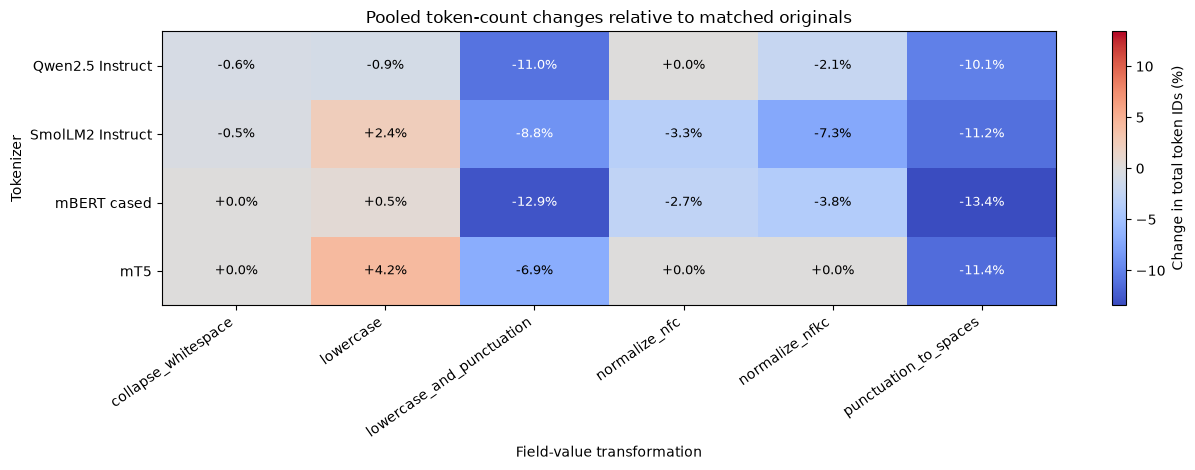

In [12]:
heatmap_table = (
    preprocessing_summary.loc[preprocessing_summary["transformation"].ne("original")]
    .pivot(index="tokenizer", columns="transformation", values="delta_percent")
    .reindex(index=list(TOKENIZER_MODELS))
)

# Convert once to a homogeneous numeric array for plotting and annotations.
heatmap_values = heatmap_table.to_numpy(dtype=float)

if not heatmap_values.size or not np.isfinite(heatmap_values).all():
    raise ValueError("The heatmap requires complete, finite numeric measurements.")

max_absolute_delta = max(1.0, float(np.abs(heatmap_values).max()))
figure, axis = plt.subplots(figsize=(13, 4.8))

image = axis.imshow(
    heatmap_values,
    cmap="coolwarm",
    vmin=-max_absolute_delta,
    vmax=max_absolute_delta,
    aspect="auto",
)

axis.set_title("Pooled token-count changes relative to matched originals")
axis.set_xlabel("Field-value transformation")
axis.set_ylabel("Tokenizer")

axis.set_xticks(
    range(len(heatmap_table.columns)), heatmap_table.columns, rotation=35, ha="right"
)

axis.set_yticks(range(len(heatmap_table.index)), heatmap_table.index)

for row_number in range(len(heatmap_table.index)):
    for column_number in range(len(heatmap_table.columns)):
        value = float(heatmap_values[row_number, column_number])

        axis.text(
            column_number,
            row_number,
            f"{value:+.1f}%",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(value) > max_absolute_delta * 0.65 else "black",
        )

figure.colorbar(image, ax=axis, label="Change in total token IDs (%)")
plt.tight_layout()
plt.show()


An aggregate reduction can hide increases for individual inputs. Furthermore, reducing a token count does not establish that the original source data were preserved. The next example examines JSON containing a path, query parameters, and a filename: JSON syntax remains valid after punctuation replacement, but the contents of the fields are changed. This is a data-integrity problem, not an encoding error.

In [13]:
largest_changes = (
    paired_df.loc[paired_df["transformation"].ne("original")]
    .assign(absolute_delta=lambda frame: frame["delta_percent"].abs())
    .sort_values("absolute_delta", ascending=False)
)

print("\nLargest individual relative changes (not necessarily safe transformations):")
display(
    largest_changes[
        [
            "case_id",
            "format",
            "tokenizer",
            "transformation",
            "original_token_count",
            "token_count",
            "delta_tokens",
            "delta_percent",
        ]
    ]
    .head(18)
    .round({"delta_percent": 2})
    .style.hide(axis="index")
)

# Compare the actual field values, not merely the validity of JSON syntax.
source_case = next(
    case for case in SOURCE_CASES if case["case_id"] == "paths_punctuation"
)
original_json = render_text(source_case["fields"], "json")
modified_json = render_text(
    transform_fields(source_case["fields"], "punctuation_to_spaces"),
    "json",
)
original_fields = json.loads(original_json)
modified_fields = json.loads(modified_json)

case_counts = paired_df.loc[
    paired_df["case_id"].eq("paths_punctuation")
    & paired_df["format"].eq("json")
    & paired_df["tokenizer"].eq("Qwen2.5 Instruct")
    & paired_df["transformation"].isin(["original", "punctuation_to_spaces"]),
    ["transformation", "token_count"],
].set_index("transformation")["token_count"]

for label, serialized in (
    ("original", original_json),
    ("punctuation_to_spaces", modified_json),
):
    print(f"\n--- {label} | {case_counts.at[label]} Qwen2.5 token IDs ---")
    print(serialized)

print(
    "\nBoth examples parse as JSON:",
    isinstance(original_fields, dict) and isinstance(modified_fields, dict),
)
print("Field values preserved:", original_fields == modified_fields)
print("Original path and parameters:", original_fields["Description"])
print("Transformed path and parameters:", modified_fields["Description"])


Largest individual relative changes (not necessarily safe transformations):


case_id,format,tokenizer,transformation,original_token_count,token_count,delta_tokens,delta_percent
paths_punctuation,plain,SmolLM2 Instruct,lowercase_and_punctuation,49,33,-16,-32.650000
paths_punctuation,plain,mBERT cased,lowercase_and_punctuation,56,38,-18,-32.140000
paths_punctuation,plain,mBERT cased,punctuation_to_spaces,56,38,-18,-32.140000
paths_punctuation,plain,SmolLM2 Instruct,punctuation_to_spaces,49,34,-15,-30.610000
paths_punctuation,markdown,SmolLM2 Instruct,lowercase_and_punctuation,54,38,-16,-29.630000
paths_punctuation,markdown,SmolLM2 Instruct,punctuation_to_spaces,54,39,-15,-27.780000
paths_punctuation,json,mBERT cased,lowercase_and_punctuation,74,54,-20,-27.030000
paths_punctuation,json,mBERT cased,punctuation_to_spaces,74,54,-20,-27.030000
html_sensitive,plain,mBERT cased,lowercase_and_punctuation,37,27,-10,-27.030000
paths_punctuation,json,SmolLM2 Instruct,lowercase_and_punctuation,63,46,-17,-26.980000



--- original | 54 Qwen2.5 token IDs ---
{
  "Title": "Logs: errors, warnings...",
  "Description": "Path /api/v1/items?limit=10&sort=asc; file name \"report-v2.json\".",
  "Tags": "slashes, punctuation, paths"
}

--- punctuation_to_spaces | 44 Qwen2.5 token IDs ---
{
  "Title": "Logs errors warnings",
  "Description": "Path api v1 items limit=10 sort=asc file name report v2 json",
  "Tags": "slashes punctuation paths"
}

Both examples parse as JSON: True
Field values preserved: False
Original path and parameters: Path /api/v1/items?limit=10&sort=asc; file name "report-v2.json".
Transformed path and parameters: Path api v1 items limit=10 sort=asc file name report v2 json


## Token representations, decoding, and information loss

Token piece strings are implementation-specific diagnostic representations. Prefixes or visible characters such as `Ġ`, `Ċ`, `##`, and `▁` are not automatically evidence of corrupt UTF-8. Inspecting `convert_ids_to_tokens` is different from reconstructing the input with `decode`.

Two additional checks use `decode(..., clean_up_tokenization_spaces=False, skip_special_tokens=False)` across all 672 measurements. `roundtrip_exact` checks whether decoding exactly reproduces the original Unicode code points, including spaces and accents. `roundtrip_nfc_equal` checks only equality after canonical NFC normalization, which is weaker than exact preservation. Neither flag measures semantic meaning or downstream task performance. Importantly, zero unknown tokens does not guarantee an exact round trip: tokenizers can normalize Unicode or whitespace internally.

In [14]:
roundtrip_summary = measurements_df.groupby("tokenizer", as_index=False).agg(
    total_conditions=("case_id", "size"),
    exact_roundtrips=("roundtrip_exact", "sum"),
    nfc_equivalent_roundtrips=("roundtrip_nfc_equal", "sum"),
    total_unknown_ids=("unknown_token_count", "sum"),
)

roundtrip_summary["non_exact_conditions"] = (
    roundtrip_summary["total_conditions"] - roundtrip_summary["exact_roundtrips"]
)

print("\nDecoded-input preservation across all input conditions:")
display(roundtrip_summary)

selected_case = next(
    case for case in SOURCE_CASES if case["case_id"] == "unicode_decomposed"
)

selected_text = render_text(selected_case["fields"], "plain")
print("\nOriginal example (repr):", repr(selected_text))

for tokenizer_name, tokenizer in tokenizers.items():
    token_ids = tokenizer.encode(selected_text, add_special_tokens=False)
    token_pieces = tokenizer.convert_ids_to_tokens(token_ids)

    reconstructed_text = tokenizer.decode(
        token_ids,
        skip_special_tokens=False,
        clean_up_tokenization_spaces=False,
    )

    print(f"\n{tokenizer_name} | {len(token_ids)} IDs")
    print("Token pieces:", token_pieces[:50])
    print("Decoded (repr):", repr(reconstructed_text))
    print("Exact match:", reconstructed_text == selected_text)
    print(
        "Equal after NFC normalization:",
        unicodedata.normalize("NFC", reconstructed_text)
        == unicodedata.normalize("NFC", selected_text),
    )


Decoded-input preservation across all input conditions:


,tokenizer,total_conditions,exact_roundtrips,nfc_equivalent_roundtrips,total_unknown_ids,non_exact_conditions
0,Qwen2.5 Instruct,168,148,168,0,20
1,SmolLM2 Instruct,168,168,168,0,0
2,mBERT cased,168,0,0,32,168
3,mT5,168,0,0,0,168



Original example (repr): 'Title: Café e coração\nDescription: A normalização Unicode pode alterar a segmentação.\nTags: acentos, Unicode, NFD'

Qwen2.5 Instruct | 29 IDs
Token pieces: ['Title', ':', 'ĠCafÃ©', 'Ġe', 'ĠcoraÃ§Ã£o', 'Ċ', 'Description', ':', 'ĠA', 'Ġnormal', 'izaÃ§Ã£o', 'ĠUnicode', 'Ġpode', 'Ġalter', 'ar', 'Ġa', 'Ġsegment', 'aÃ§Ã£o', '.Ċ', 'Tags', ':', 'Ġa', 'cent', 'os', ',', 'ĠUnicode', ',', 'ĠN', 'FD']
Decoded (repr): 'Title: Café e coração\nDescription: A normalização Unicode pode alterar a segmentação.\nTags: acentos, Unicode, NFD'
Exact match: False
Equal after NFC normalization: True

SmolLM2 Instruct | 49 IDs
Token pieces: ['Title', ':', 'ĠC', 'afe', 'Ì', 'ģ', 'Ġe', 'Ġcor', 'ac', 'Ì', '§', 'a', 'Ì', 'ĥ', 'o', 'Ċ', 'Description', ':', 'ĠA', 'Ġnormal', 'iz', 'ac', 'Ì', '§', 'a', 'Ì', 'ĥ', 'o', 'ĠUnicode', 'Ġp', 'ode', 'Ġalter', 'ar', 'Ġa', 'Ġsegment', 'a', 'Ã§Ã£o', '.', 'Ċ', 'Tags', ':', 'Ġac', 'ent', 'os', ',', 'ĠUnicode', ',', 'ĠNF', 'D']
Decoded (repr): 'Titl

**RQ3 conclusion.** Preprocessing effects are tokenizer-dependent, and a lower count is not a quality metric. In the provided run, lowercasing increased aggregate token counts for SmolLM2 (**+2.38%**) and mT5 (**+4.20%**) even though it slightly reduced the Qwen2.5 total (**-0.87%**).

Replacing punctuation with spaces reduced totals for all four tokenizers (approximately **-10% to -13%**) but damaged technical content such as paths and filenames. NFC had a zero token-count effect for Qwen2.5 and mT5 in the pooled data; this does not mean Unicode normalization is irrelevant or that all input strings round-trip exactly. NFKC may change the identity of characters.


**Overall conclusion.** Token counts are properties of the **input string and tokenizer configuration**. Before preprocessing or changing serialization in a real system, define what information must be preserved, then measure the desired downstream behavior and any provider-specific accounting separately. The examples here support hypotheses for larger, representative experiments; they do not justify universal optimization rules.

## Research summary and limitations

| Question | Observed pattern in the provided run | What is **not** established |
|---|---|---|
| RQ1: tokenizer choice | Token-count ranges differed across the six identical plain-text inputs; the largest range was 37-60 IDs. | Model accuracy, inference speed, or billed cost. |
| RQ2: serialization | For these templates, HTML had the largest aggregate overhead relative to plain text; Markdown and JSON also increased aggregate totals. | A universal ranking of data formats or downstream utility. |
| RQ3: preprocessing | Lowercasing could increase token counts; punctuation replacement often reduced counts but altered technical values. | Semantic equivalence, information preservation, or an optimal universal preprocessing strategy. |